In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from pathlib import Path
import numpy as np
import pandas as pd
import torch

import os
import sys
# walk up from the cwd to the repo root, so re-running this cell after the chdir still works
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "train_baseline.py").exists())
os.chdir(PROJECT_DIR)
for d in [PROJECT_DIR / "src", PROJECT_DIR / "src" / "splits"]:
    if str(d) not in sys.path:
        sys.path.insert(0, str(d))

from make_split import make_split
from utils import run_dir
import train_baseline as tb      # reuse the model, dataset and helpers from the training script

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cpu


In [39]:
ORIENTATION = "sagittal"
TARGET_SHAPE = (96,96,96)
SEED = 42
SPLITS = ["test"]                # which splits to run the model on
MANIFEST = Path(f"{PROJECT_DIR}/data/manifest_{ORIENTATION}.csv")
RUN_DIR = run_dir(ORIENTATION, TARGET_SHAPE, SEED, project_dir=PROJECT_DIR)
CHECKPOINT = RUN_DIR / "best_model.pt"
SAVE_DIR = Path(f"{PROJECT_DIR}/results/stress_tests/{ORIENTATION}_{TARGET_SHAPE[0]}{TARGET_SHAPE[1]}{TARGET_SHAPE[2]}_{SEED}")
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir(parents=True, exist_ok=True)

# reuse the split the model was trained on (don't remake it, or training subjects can leak into test)
manifest = pd.read_csv(MANIFEST)
saved = pd.read_csv(RUN_DIR / "manifest_split.csv")[["sub_id", "split"]].drop_duplicates("sub_id")
manifest = manifest.merge(saved, on="sub_id", how="left")
assert not manifest["split"].isna().any(), "some subjects in the manifest are missing from the saved split"

print("Base split:")
print(    "Train:", len(manifest[manifest["split"] == "train"]),
          "Val:", len(manifest[manifest["split"] == "val"]),
          "Test:", len(manifest[manifest["split"] == "test"]))

Base split:
Train: 511 Val: 110 Test: 110


In [8]:
model = tb.Baseline3DCNN().to(device)
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.eval()

inspect_df = manifest[manifest["split"].isin(SPLITS)]
pred = tb.per_subject(tb.predict(model, inspect_df, batch_size=4, device=device))
print(f"{len(pred)} subjects in {SPLITS}; autism fraction {pred['label'].mean():.2f}")
pred.head()

110 subjects in ['test']; autism fraction 0.49


,sub_id,label,site,prob
0,50003,1,PITT,0.533815
1,50015,1,PITT,0.560408
2,50022,1,PITT,0.533132
3,50023,1,PITT,0.490095
4,50041,0,PITT,0.491418


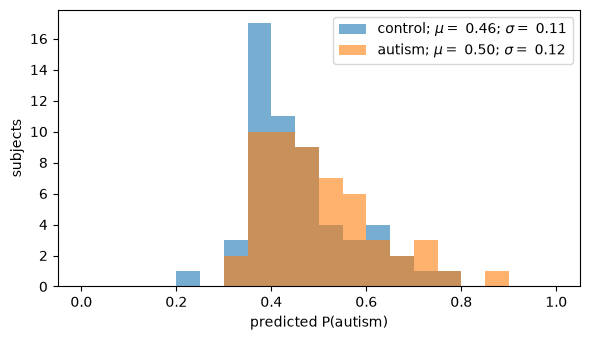

In [40]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for lab, name in [(0, "control"), (1, "autism")]:
    p = pred.loc[pred["label"] == lab, "prob"]
    ax.hist(p, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p.mean():.2f}; $\\sigma=$ {p.std():.2f}")
ax.set_xlabel("predicted P(autism)"); ax.set_ylabel("subjects"); ax.legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/dx_groups.png")
plt.show()

## Check Specific Populations

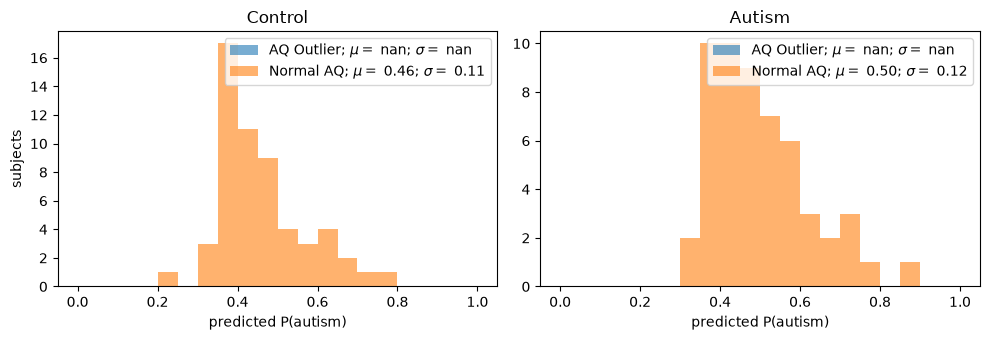

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for val, name in [(True, "AQ Outlier"), (False, "Normal AQ")]:
    control_id = manifest[(manifest["aq_outlier"] == val) & (manifest["label"] == 0)]["sub_id"]
    autism_id = manifest[(manifest["aq_outlier"] == val) & (manifest["label"] == 1)]["sub_id"]
    p_autism = pred.loc[pred["sub_id"].isin(autism_id), "prob"]
    p_control = pred.loc[pred["sub_id"].isin(control_id), "prob"]
    ax[0].set_title("Control")
    ax[0].hist(p_control, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_control.mean():.2f}; $\\sigma=$ {p_control.std():.2f}")
    ax[1].set_title("Autism")
    ax[1].hist(p_autism, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_autism.mean():.2f}; $\\sigma=$ {p_autism.std():.2f}")
ax[0].set_xlabel("predicted P(autism)"); ax[1].set_xlabel("predicted P(autism)"); ax[0].set_ylabel("subjects"); ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/aq_outliers.png")
plt.show()

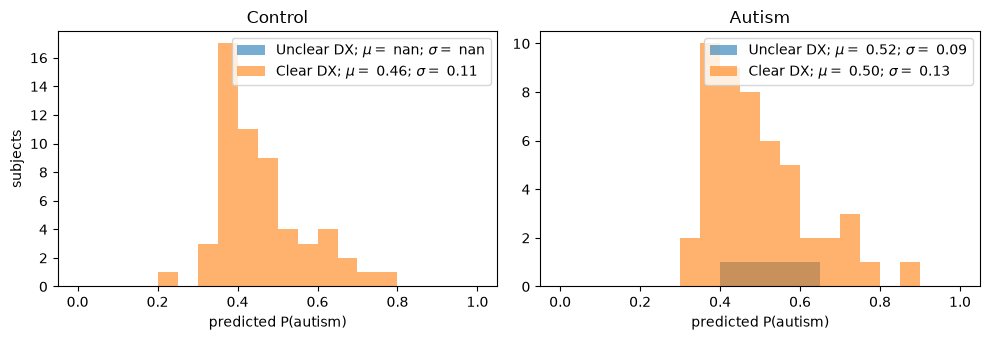

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for val, name in [(True, "Unclear DX"), (False, "Clear DX")]:
    control_id = manifest[(manifest["unclear_diag"] == val) & (manifest["label"] == 0)]["sub_id"]
    autism_id = manifest[(manifest["unclear_diag"] == val) & (manifest["label"] == 1)]["sub_id"]
    p_autism = pred.loc[pred["sub_id"].isin(autism_id), "prob"]
    p_control = pred.loc[pred["sub_id"].isin(control_id), "prob"]
    ax[0].set_title("Control")
    ax[0].hist(p_control, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_control.mean():.2f}; $\\sigma=$ {p_control.std():.2f}")
    ax[1].set_title("Autism")
    ax[1].hist(p_autism, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_autism.mean():.2f}; $\\sigma=$ {p_autism.std():.2f}")
ax[0].set_xlabel("predicted P(autism)"); ax[1].set_xlabel("predicted P(autism)"); ax[0].set_ylabel("subjects"); ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/unclear_dx.png")
plt.show()

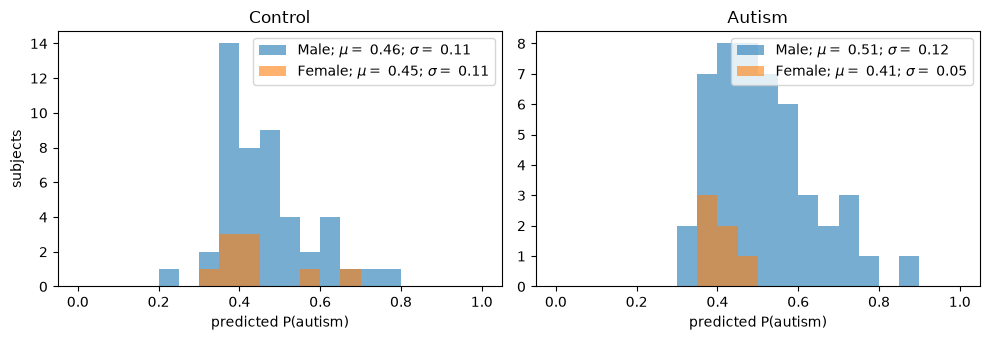

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for val, name in [(1, "Male"), (2, "Female")]:
    control_id = manifest[(manifest["sex"] == val) & (manifest["label"] == 0)]["sub_id"]
    autism_id = manifest[(manifest["sex"] == val) & (manifest["label"] == 1)]["sub_id"]
    p_autism = pred.loc[pred["sub_id"].isin(autism_id), "prob"]
    p_control = pred.loc[pred["sub_id"].isin(control_id), "prob"]
    ax[0].set_title("Control")
    ax[0].hist(p_control, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_control.mean():.2f}; $\\sigma=$ {p_control.std():.2f}")
    ax[1].set_title("Autism")
    ax[1].hist(p_autism, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_autism.mean():.2f}; $\\sigma=$ {p_autism.std():.2f}")
ax[0].set_xlabel("predicted P(autism)"); ax[1].set_xlabel("predicted P(autism)"); ax[0].set_ylabel("subjects"); ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/sex.png")
plt.show()

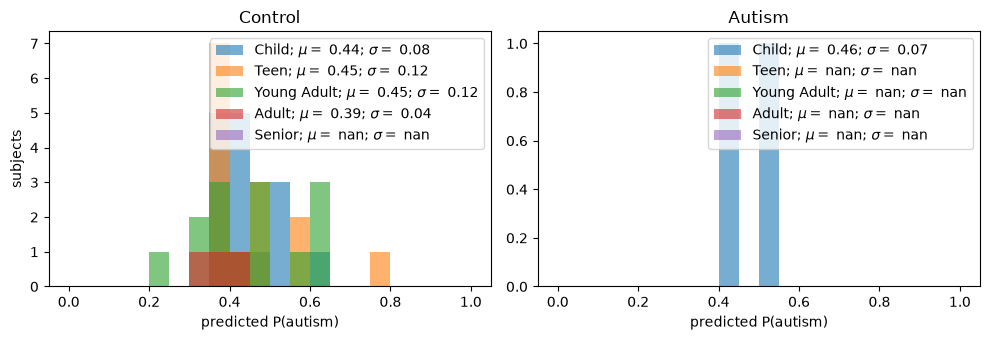

In [44]:
age_groups = [(0,12),(13,18),(19,29),(30,55),(66,100)]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for val, name in [
    (age_groups[0], "Child"), 
    (age_groups[1], "Teen"), 
    (age_groups[2], "Young Adult"),
    (age_groups[3], "Adult"),
    (age_groups[4], "Senior")]:
    control_id = manifest[(manifest["age"] > val[0]) & (manifest["age"] <= val[1]) & (manifest["label"] == 0)]["sub_id"]
    autism_id = manifest[(manifest["unclear_diag"] > val[0]) & (manifest["age"] <= val[1]) & (manifest["label"] == 1)]["sub_id"]
    p_autism = pred.loc[pred["sub_id"].isin(autism_id), "prob"]
    p_control = pred.loc[pred["sub_id"].isin(control_id), "prob"]
    ax[0].set_title("Control")
    ax[0].hist(p_control, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_control.mean():.2f}; $\\sigma=$ {p_control.std():.2f}")
    ax[1].set_title("Autism")
    ax[1].hist(p_autism, bins=np.linspace(0, 1, 21), alpha=0.6, 
    label=f"{name}; $\\mu=$ {p_autism.mean():.2f}; $\\sigma=$ {p_autism.std():.2f}")
ax[0].set_xlabel("predicted P(autism)"); ax[1].set_xlabel("predicted P(autism)"); ax[0].set_ylabel("subjects"); ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/age_groups.png")
plt.show()